# Metaheuristics for Multi-Resource Workload Allocation
### Hardware-constrained AI model selection (0-1 multidimensional knapsack)

**Student ID:** 30068136  **Module:** Artificial Intelligence, coursework (100 marks)

| Section | Content | Instance |
|---|---|---|
| 0 | Setup, data ingestion, reference optimum, correctness checks | both |
| 1 | Shared, modular solver library (evaluator, constraint handlers, operators, algorithms, statistics) | – |
| **Part 1** | Baseline hill climber + comparison of three constraint-handling strategies | n=28, m=2 |
| **Part 2** | Steady-state GA with LP-dual surrogate repair | n=90, m=5 |
| **Part 3** | Two controlled experiments (H1: repair vs penalty, H2: dual vs naive repair weights), M=30, Mann–Whitney U + Vargha–Delaney A12 | n=90, m=5 |
| 4 | Conclusions, threats to validity, references | – |

**Reproducibility.** `numpy.random.seed(42)` is set globally, and every run *k* uses its own generator `np.random.default_rng(42 + k)`. All numbers below can be regenerated with *Kernel → Restart & Run All* (about 15 min on a laptop CPU). Only `numpy`, `scipy`, `pandas` and `matplotlib` are used. All search logic is written from scratch.

## 0. Setup and data ingestion

In [1]:
import time, itertools
from pathlib import Path
from dataclasses import dataclass, field
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import milp, linprog, LinearConstraint, Bounds
from scipy.stats import mannwhitneyu, spearmanr
from workload_data_loader import load_workload_instance   # provided helper

MASTER_SEED = 42
np.random.seed(MASTER_SEED)            # global seed (required); all runs also use explicit generators
N_RUNS = 30                            # M >= 30 independent runs everywhere
pd.set_option("display.precision", 2)

# Plot style: validated categorical palette (first three slots), thin marks, recessive grid
C = {"blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a", "ink": "#0b0b0b", "muted": "#52514e"}
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e6e6", "grid.linewidth": 0.8,
    "axes.edgecolor": "#9a9993", "axes.labelcolor": C["ink"], "xtick.color": C["muted"],
    "ytick.color": C["muted"], "lines.linewidth": 2, "legend.frameon": False, "font.size": 10,
})

In [2]:
@dataclass
class Instance:
    name: str
    n: int
    m: int
    p: np.ndarray          # utilities, shape (n,)
    R: np.ndarray          # demands, shape (m, n)
    b: np.ndarray          # capacities, shape (m,)
    optimum: float = None  # exact optimum (MILP), reporting only
    lp_bound: float = None
    duals: np.ndarray = None

def load(path, name):
    n, m, p, R, b = load_workload_instance(path)
    assert p.shape == (n,) and R.shape == (m, n) and b.shape == (m,)
    assert (R >= 0).all() and (p > 0).all()
    assert (R <= b[:, None]).all(), "every single model fits on its own"
    return Instance(name, n, m, p, R, b)

def find_data_file(*names, folders=(".", "data")):
    # accept the file next to this notebook or in ./data, under any of the given names
    for folder in folders:
        for name in names:
            path = Path(folder) / name
            if path.exists():
                return str(path)
    raise FileNotFoundError(f"Cannot find {names[0]}. Place it in the same folder as this notebook.")

I1 = load(find_data_file("multi_resource_n28_m2.txt"), "Instance 1 (n=28, m=2)")
I2 = load(find_data_file("multi_resource_n90_m5.txt", "multi_resource_n90_m5 (1).txt"), "Instance 2 (n=90, m=5)")
print("loaded:", find_data_file("multi_resource_n28_m2.txt"), "|",
      find_data_file("multi_resource_n90_m5.txt", "multi_resource_n90_m5 (1).txt"))

pd.DataFrame([{
    "instance": I.name, "n": I.n, "m": I.m, "search space": f"2^{I.n} = {2.0**I.n:.2e}",
    "capacities b": I.b.astype(int).tolist(),
    "tightness  b / sum_j r_ij": np.round(I.b / I.R.sum(1), 2).tolist(),
} for I in (I1, I2)])

loaded: multi_resource_n28_m2.txt | multi_resource_n90_m5 (1).txt


,instance,n,m,search space,capacities b,tightness b / sum_j r_ij
0,"Instance 1 (n=28, m=2)",28,2,2^28 = 2.68e+08,"[500, 500]","[0.44, 0.5]"
1,"Instance 2 (n=90, m=5)",90,5,2^90 = 1.24e+27,"[2100, 1100, 3300, 3700, 3600]","[0.63, 0.33, 0.85, 0.95, 0.91]"


### 0.1 Reference optimum and LP relaxation (used for reporting and repair design, never as a solver)
The search space is small enough for an exact MILP solver (HiGHS, via `scipy.optimize.milp`) to find the **global optimum**. It is used **only** to report the optimality gap and the success rate (whether a run reaches the optimum). No metaheuristic ever calls it.

The **LP relaxation** (x ∈ [0,1]ⁿ) also gives the dual price $y_i$ of each resource constraint. By LP duality, $y_i>0$ only for resources that are scarce at the optimum. Section 2.2 uses these prices as surrogate weights in the repair operator, the classic approach of Pirkul (1987) and Chu & Beasley (1998).

In [3]:
def solve_reference(I):
    # exact optimum (MILP) + LP relaxation duals; reporting / repair design only
    res = milp(-I.p, constraints=LinearConstraint(I.R, -np.inf, I.b),
               integrality=np.ones(I.n), bounds=Bounds(0, 1))
    lp = linprog(-I.p, A_ub=I.R, b_ub=I.b, bounds=(0, 1), method="highs")
    x_opt = np.round(res.x).astype(int)
    assert (I.R @ x_opt <= I.b).all()
    I.optimum = float(I.p @ x_opt)                 # exact value from the integer vector (no float noise)
    I.lp_bound, I.duals = -lp.fun, -lp.ineqlin.marginals
    return x_opt

for I in (I1, I2):
    x_opt = solve_reference(I)
    print(f"{I.name}: optimum f* = {I.optimum:,.0f}  ({x_opt.sum()} models)  "
          f"LP bound = {I.lp_bound:,.1f}\n   resource use at optimum = {(I.R @ x_opt).astype(int)}  "
          f"vs b = {I.b.astype(int)}\n   LP dual prices y = {np.round(I.duals, 3)}")

Instance 1 (n=28, m=2): optimum f* = 130,883  (11 models)  LP bound = 131,637.5
   resource use at optimum = [495 499]  vs b = [500 500]
   LP dual prices y = [  4.4  107.28]
Instance 2 (n=90, m=5): optimum f* = 11,191  (51 models)  LP bound = 11,194.7
   resource use at optimum = [1777 1100 2259 2232 2418]  vs b = [2100 1100 3300 3700 3600]
   LP dual prices y = [0.    2.769 0.    0.    0.   ]


**Observation that shapes the design.** On Instance 2 only **resource 2** has a non-zero dual price, and it is the only resource used to 100 % at the optimum (1100/1100). The other four have 15–40 % slack. The problem therefore behaves almost like a single-constraint knapsack on resource 2. A repair rule that weights all five resources equally will mis-rank models (tested as hypothesis H2 in Part 3). On Instance 1 both resources are tight (495/500 and 499/500).

## 1. Shared solver library
All algorithms are built from the same small set of interchangeable components, so experiments differ **only** in the component under test:

| Component | Responsibility |
|---|---|
| `Evaluator` | the **only** way to compute f(x). Enforces the fitness-evaluation budget, counts feasible candidates, and records the best-feasible-so-far trace after every evaluation |
| `ConstraintHandler` subclasses | `initial()` builds a starting solution, `prepare()` is applied before evaluation (e.g. repair), `fitness()` is the selection score |
| operators | neighbourhood moves (HC), tournament selection, uniform crossover, bit-flip mutation (GA) |
| `hill_climber`, `steady_state_ga` | search logic, independent of the constraint-handling strategy |
| `run_many`, `compare` | M independent seeded runs, summary table, Mann–Whitney U, A12, Holm correction |

In [4]:
class Evaluator:
    # Budgeted objective function. One call to evaluate() = one fitness evaluation.
    def __init__(self, inst, budget):
        self.I, self.budget, self.used, self.n_feasible = inst, int(budget), 0, 0
        self.best_util, self.best_x = 0.0, None          # best FEASIBLE solution seen
        self.trace = np.zeros(self.budget)               # best-feasible-so-far after each evaluation

    @property
    def remaining(self):
        return self.budget - self.used

    def evaluate(self, x):
        assert self.used < self.budget, "evaluation budget exceeded"
        util = float(self.I.p @ x)
        violation = float(np.maximum(self.I.R @ x - self.I.b, 0).sum())   # total capacity overflow
        if violation == 0:
            self.n_feasible += 1
            if util > self.best_util:
                self.best_util, self.best_x = util, x.copy()
        self.trace[self.used] = self.best_util
        self.used += 1
        return util, violation

    def result(self):
        if self.used < self.budget:                      # (early stop) carry the best value forward
            self.trace[self.used:] = self.best_util
        opt = self.I.optimum
        hit = np.flatnonzero(self.trace >= opt)
        return {"best_utility": self.best_util,
                "gap_%": 100 * (opt - self.best_util) / opt,
                "hit_optimum": self.best_util >= opt,
                "evals_to_opt": hit[0] + 1 if hit.size else np.nan,
                "feasible_rate": self.n_feasible / max(self.used, 1),
                "evals_used": self.used}

### 1.1 Constraint-handling strategies
Three strategies from the standard classification (Coello Coello, 2002):

* **Death penalty**: infeasible candidates get fitness −∞ and are never accepted. The search starts from a random feasible point, obtained by removing random models until all constraints hold.
* **Static penalty**: $F(x)=f(x)-\lambda\sum_i\max(0,\;R_i x-b_i)$ with $\lambda=\max_{i,j:\,r_{ij}>0} p_j/r_{ij}$. One unit of overflow then costs at least as much utility as any model can earn per unit of resource, so a solution is never rewarded for breaking a constraint (Olsen, 1994). Infeasible candidates stay in the search and can serve as stepping stones.
* **Greedy surrogate repair** (Chu & Beasley, 1998): each model gets a pseudo-utility ratio $u_j = p_j / \sum_i w_i r_{ij}$. **DROP**: while infeasible, remove selected models in increasing $u_j$ order. **ADD**: then insert unselected models in decreasing $u_j$ order whenever they fit. The output is always feasible *and maximal* (no further model fits). The repaired vector replaces the original (Lamarckian). The weights *w* are a design choice: `w = dual prices y` (default) or `w = 1/b` (capacity-normalised sum, tested in H2). A tiny tie-break term δ/b keeps every resource in the ratio so the order is fully defined.
  *Move-preserving variant*: `prepare(x, keep, ban)` never drops the model a move just inserted (`keep`) and never re-adds the one it just removed (`ban`). Without this, the repair often undoes the move and the hill climber wastes evaluations on unchanged solutions.

The ratio order is sorted **once** (O(n log n)). Each repair is O(n·m), and the ADD phase pre-filters to the models that fit the current slack, because slack only shrinks.

In [5]:
class ConstraintHandler:
    name = "base"
    def __init__(self, inst): self.I = inst
    def initial(self, rng):  return (rng.random(self.I.n) < 0.5).astype(np.int8)
    def prepare(self, x, keep=-1, ban=-1): return x
    def fitness(self, util, violation): raise NotImplementedError

class DeathPenalty(ConstraintHandler):
    name = "Death penalty"
    def initial(self, rng):
        x = super().initial(rng)
        while (self.I.R @ x > self.I.b).any():                 # drop random models until feasible
            x[rng.choice(np.flatnonzero(x))] = 0
        return x
    def fitness(self, util, violation):
        return util if violation == 0 else -np.inf

class StaticPenalty(ConstraintHandler):
    name = "Static penalty"
    def __init__(self, inst):
        super().__init__(inst)
        ratios = inst.p[None, :] / np.where(inst.R > 0, inst.R, np.nan)
        self.lam = np.nanmax(ratios)
    def fitness(self, util, violation):
        return util - self.lam * violation

class GreedyRepair(ConstraintHandler):
    def __init__(self, inst, weights, name):
        super().__init__(inst)
        self.name = name
        w = weights + 1e-6 * weights.max() * inst.b.mean() / inst.b     # tie-break: keep every resource
        self.ratio = inst.p / (w @ inst.R)                               # pseudo-utility u_j
        self.drop_order = np.argsort(self.ratio, kind="stable")          # worst ratio first
        self.add_order = self.drop_order[::-1].copy()                    # best ratio first
        self.RT = np.ascontiguousarray(inst.R.T)                         # (n, m) rows = models

    def initial(self, rng):
        return self.prepare(super().initial(rng))

    def prepare(self, x, keep=-1, ban=-1):
        x, RT, b = x.copy(), self.RT, self.I.b
        load = self.I.R @ x
        if (load > b).any():                                   # DROP phase
            for j in self.drop_order:
                if x[j] and j != keep:
                    x[j] = 0
                    load -= RT[j]
                    if (load <= b).all():
                        break
        slack = b - load                                       # ADD phase (pre-filtered)
        cand = self.add_order[(x[self.add_order] == 0) & (RT[self.add_order] <= slack).all(1)]
        for j in cand:
            if j != ban and (RT[j] <= slack).all():
                x[j] = 1
                slack -= RT[j]
        return x

    def fitness(self, util, violation):
        return util if violation == 0 else -np.inf             # never happens: output is always feasible

def dual_repair(I):   return GreedyRepair(I, I.duals, "Repair (LP-dual weights)")
def naive_repair(I):  return GreedyRepair(I, 1.0 / I.b, "Repair (capacity-normalised weights)")

### 1.2 Variation operators

In [6]:
def neighbour(x, rng, p_swap=0.5):
    # Hill-climbing move. Returns (y, keep, ban) so a repair operator can preserve the move.
    # flip : toggle one random model (add or remove)
    # swap : remove one selected model and add one unselected model (keeps cardinality)
    y, ones = x.copy(), np.flatnonzero(x)
    if rng.random() < p_swap and 0 < ones.size < x.size:
        i, j = rng.choice(ones), rng.choice(np.flatnonzero(x == 0))
        y[i], y[j] = 0, 1
        return y, j, i
    j = rng.integers(x.size)
    y[j] ^= 1
    return (y, j, -1) if y[j] else (y, -1, j)

def tournament(fit, rng, k=2):
    idx = rng.integers(fit.size, size=k)
    return idx[np.argmax(fit[idx])]

def uniform_crossover(a, b, rng):
    return np.where(rng.random(a.size) < 0.5, a, b)

def bit_flip(x, pm, rng):
    return x ^ (rng.random(x.size) < pm).astype(np.int8)

### 1.3 Algorithms
**Stochastic hill climber (Part 1).** Starts from `handler.initial()` and proposes one random neighbour per evaluation (flip or swap). It accepts the neighbour if `fitness ≥ current` (sideways moves let it cross plateaus of equal utility). After `stall` consecutive non-improving evaluations it **restarts** from a fresh random solution. The best feasible solution is never lost, because the evaluator stores it.

**Steady-state GA (Part 2).** A population of μ distinct solutions. Each step creates **one** child: binary tournament → uniform crossover → bit-flip mutation (pₘ = 1/n) → `handler.prepare()` → evaluate. The child replaces the worst member if it is at least as fit. Children identical to an existing member are discarded **before** evaluation (hash set), so no budget is spent on known solutions and diversity is maintained. Population diversity (mean pairwise Hamming distance / n) is logged every μ evaluations.

In [7]:
def hill_climber(I, handler, budget, rng, stall=300, p_swap=0.5):
    ev = Evaluator(I, budget)
    def start():
        x = handler.initial(rng)
        return x, handler.fitness(*ev.evaluate(x))
    cur, f_cur = start()
    since, restarts = 0, 0
    while ev.remaining:
        y, keep, ban = neighbour(cur, rng, p_swap)
        y = handler.prepare(y, keep, ban)
        f_y = handler.fitness(*ev.evaluate(y))
        since = 0 if f_y > f_cur else since + 1
        if f_y >= f_cur:
            cur, f_cur = y, f_y
        if since >= stall and ev.remaining:
            cur, f_cur = start()
            since, restarts = 0, restarts + 1
    return {**ev.result(), "restarts": restarts}, ev

def steady_state_ga(I, handler, budget, rng, pop_size=100, pm=None, k=2):
    ev, n = Evaluator(I, budget), I.n
    pm = 1.0 / n if pm is None else pm
    pop, fit, seen = [], [], set()
    while len(pop) < pop_size and ev.remaining:            # distinct initial population
        x = handler.initial(rng)
        if x.tobytes() in seen:
            continue
        seen.add(x.tobytes()); pop.append(x); fit.append(handler.fitness(*ev.evaluate(x)))
    pop, fit = np.array(pop), np.array(fit)
    diversity, dup, streak = [], 0, 0
    while ev.remaining and streak < 10_000:
        c = uniform_crossover(pop[tournament(fit, rng, k)], pop[tournament(fit, rng, k)], rng)
        c = handler.prepare(bit_flip(c, pm, rng))
        key = c.tobytes()
        if key in seen:                                    # duplicate: discard without evaluating
            dup += 1; streak += 1
            continue
        streak = 0
        f = handler.fitness(*ev.evaluate(c))
        w = np.argmin(fit)
        if f >= fit[w]:
            seen.discard(pop[w].tobytes()); seen.add(key)
            pop[w], fit[w] = c, f
        if ev.used % pop_size == 0:
            q = pop.mean(0)
            diversity.append(2 * (q * (1 - q)).sum() / n * pop_size / (pop_size - 1))
    return {**ev.result(), "duplicates_skipped": dup}, ev, np.array(diversity)

In [8]:
def run_many(algo, I, make_handler, budget, n_runs=N_RUNS, label=None, **kw):
    # M independent runs. Run k uses np.random.default_rng(MASTER_SEED + k).
    rows, traces, extras = [], [], []
    for k in range(n_runs):
        rng = np.random.default_rng(MASTER_SEED + k)
        handler = make_handler(I)
        t0 = time.perf_counter()
        out = algo(I, handler, budget, rng, **kw)
        elapsed = time.perf_counter() - t0
        res, ev = out[0], out[1]
        assert ev.best_x is not None and (I.R @ ev.best_x <= I.b).all()   # independent feasibility audit
        rows.append({"variant": label or handler.name, "run": k, **res, "time_s": elapsed})
        traces.append(ev.trace.copy())
        extras.append(out[2] if len(out) > 2 else None)
    return pd.DataFrame(rows), np.array(traces), extras

def summarise(df):
    g = df.groupby("variant", sort=False)
    out = pd.DataFrame({
        "mean": g.best_utility.mean(), "std": g.best_utility.std(), "median": g.best_utility.median(),
        "best": g.best_utility.max(), "worst": g.best_utility.min(),
        "mean gap %": g["gap_%"].mean(), "success %": 100 * g.hit_optimum.mean(),
        "median evals→opt": g.evals_to_opt.median(), "feasible cand. %": 100 * g.feasible_rate.mean(),
        "time/run (s)": g.time_s.mean(), "µs / eval": 1e6 * g.time_s.sum() / g.evals_used.sum(),
    })
    if "duplicates_skipped" in df:                    # GA only: children discarded before evaluation
        out["dup. skipped / run"] = g.duplicates_skipped.mean()
    return out

def a12(a, b):
    # Vargha-Delaney A12 = P(A > B) + 0.5 P(A = B)
    a, b = np.asarray(a, float)[:, None], np.asarray(b, float)[None, :]
    return (a > b).mean() + 0.5 * (a == b).mean()

def a12_magnitude(A):
    d = abs(A - 0.5)
    return "negligible" if d < 0.06 else "small" if d < 0.14 else "medium" if d < 0.21 else "large"

def compare(a, b, alternative):
    a, b = np.asarray(a, float), np.asarray(b, float)
    if np.unique(np.concatenate([a, b])).size == 1:
        U, p = a.size * b.size / 2, 1.0                    # all values identical: no evidence of difference
    else:
        U, p = mannwhitneyu(a, b, alternative=alternative)
    A = a12(a, b)
    return {"median A": np.median(a), "median B": np.median(b), "U": U, "p": p,
            "A12": A, "effect": a12_magnitude(A)}

def holm(pvals):
    # Holm-Bonferroni adjusted p-values
    p = np.asarray(pvals); order = np.argsort(p); adj = np.empty_like(p, dtype=float)
    running = 0
    for rank, i in enumerate(order):
        running = max(running, (len(p) - rank) * p[i]); adj[i] = min(1.0, running)
    return adj

In [9]:
def plot_convergence(ax, traces, colors, optimum, title, logx=True, ylim=None):
    # median best-so-far with inter-quartile band, one line per variant
    for (name, T), col in zip(traces.items(), colors):
        x = np.arange(1, T.shape[1] + 1)
        q1, med, q3 = np.percentile(T, [25, 50, 75], axis=0)
        ax.fill_between(x, q1, q3, color=col, alpha=0.18, linewidth=0)
        ax.plot(x, med, color=col, label=f"{name} (median, IQR band)")
    ax.axhline(optimum, color=C["muted"], ls="--", lw=1)
    ax.annotate(f"optimum {optimum:,.0f}", (1, optimum), xycoords=("axes fraction", "data"),
                ha="right", va="bottom", fontsize=8, color=C["muted"])
    if logx: ax.set_xscale("log")
    if ylim: ax.set_ylim(*ylim)
    ax.set(xlabel="fitness evaluations" + (" (log scale)" if logx else ""),
           ylabel="best feasible utility so far", title=title)
    ax.legend(loc="lower right", fontsize=8)

def plot_box(ax, data, colors, title, ylabel="best utility at end of budget", optimum=None):
    names = list(data)
    bp = ax.boxplot([data[k] for k in names], widths=0.5, patch_artist=True,
                    medianprops=dict(color=C["ink"], lw=1.5), showmeans=True,
                    meanprops=dict(marker="D", markerfacecolor="white", markeredgecolor=C["ink"], markersize=6))
    for patch, col in zip(bp["boxes"], colors):
        patch.set(facecolor=col, alpha=0.55, edgecolor=col)
    rng = np.random.default_rng(0)
    for i, (k, col) in enumerate(zip(names, colors), start=1):      # show every run (M=30)
        ax.scatter(i + rng.uniform(-0.12, 0.12, len(data[k])), data[k], s=10, color=col, zorder=3, alpha=0.8)
    if optimum is not None:
        ax.axhline(optimum, color=C["muted"], ls="--", lw=1)
    ax.set_xticks(range(1, len(names) + 1), [k.replace(" (", "\n(") for k in names], fontsize=8)
    ax.set(title=title, ylabel=ylabel)

### 1.4 Correctness checks
The search results are only meaningful if the building blocks are correct, so these checks run before any experiment:
1. The repair output is **always feasible and maximal** (10,000 random vectors per instance, both weightings).
2. The `Evaluator` refuses to exceed its budget.
3. The MILP reference is validated against **exhaustive enumeration** on a 20-model sub-problem (2²⁰ ≈ 10⁶ states).

In [10]:
rng = np.random.default_rng(MASTER_SEED)
for I in (I1, I2):
    for H in (dual_repair(I), naive_repair(I)):
        for _ in range(10_000):
            x = H.prepare((rng.random(I.n) < rng.random()).astype(np.int8))
            load = I.R @ x
            assert (load <= I.b).all()                                      # feasible
            assert not ((I.R[:, x == 0] <= (I.b - load)[:, None]).all(0)).any()   # maximal
print("1. repair: 40,000 random vectors -> all feasible and maximal")

ev = Evaluator(I1, 3); [ev.evaluate(np.zeros(I1.n, np.int8)) for _ in range(3)]
try:
    ev.evaluate(np.zeros(I1.n, np.int8)); raise RuntimeError("budget not enforced")
except AssertionError:
    print("2. evaluator: budget strictly enforced")

sub = slice(0, 20); p, R, b = I1.p[sub], I1.R[:, sub], I1.b * 0.6
X = ((np.arange(2**20)[:, None] >> np.arange(20)) & 1).astype(np.int8)
brute = (X @ p)[((X @ R.T) <= b).all(1)].max()
exact = -milp(-p, constraints=LinearConstraint(R, -np.inf, b), integrality=np.ones(20), bounds=Bounds(0, 1)).fun
print(f"3. exhaustive search = {brute:,.0f}, MILP = {exact:,.0f} -> {'match' if brute == exact else 'MISMATCH'}")
del X

1. repair: 40,000 random vectors -> all feasible and maximal
2. evaluator: budget strictly enforced


3. exhaustive search = 79,955, MILP = 79,955 -> match


---
## Part 1: Baseline discrete local search (Instance 1, n = 28, m = 2)

### 1.1 Design choices
| Element | Choice | Rationale |
|---|---|---|
| Representation | binary vector x ∈ {0,1}²⁸ | matches the decision variables directly; every operator stays inside the space |
| Initialisation | uniform random bits (p = 0.5), then the handler's own initialiser | unbiased starting point; each handler decides how to reach feasibility |
| Move operator (mutation) | **flip** (p = 0.5) or **swap** 1-out/1-in (p = 0.5) | A good solution is nearly full on both resources (the optimum uses 495/500 and 499/500). From such a point, adding a model breaks a constraint and removing one lowers utility, so *flip-only* climbers stall quickly. **Swap** exchanges models at roughly constant load, which is the move that improves a full knapsack |
| Acceptance | first-improvement, accept if fitness ≥ current | evaluates one neighbour at a time (cheap); sideways moves cross plateaus |
| Escape | random restart after 300 non-improving evaluations | the climber is otherwise trapped at the first local optimum |
| Budget | **3,000 evaluations per run**, M = 30 runs | identical for all strategies |

**Constraint-strategy test.** The same climber is run with the three handlers from §1.1 (death penalty, static penalty, LP-dual repair). Only the constraint handling differs, so its effect is isolated.

In [11]:
P1_BUDGET = 3_000
p1_handlers = {"Death penalty": DeathPenalty, "Static penalty": StaticPenalty, "Repair (LP-dual weights)": dual_repair}
p1_df, p1_tr = [], {}
for name, H in p1_handlers.items():
    df, tr, _ = run_many(hill_climber, I1, H, P1_BUDGET, label=name)
    p1_df.append(df); p1_tr[name] = tr
p1_df = pd.concat(p1_df, ignore_index=True)
summarise(p1_df)

,mean,std,median,best,worst,mean gap %,success %,median evals→opt,feasible cand. %,time/run (s),µs / eval
variant,,,,,,,,,,,
Death penalty,116765.37,5211.02,117360.0,128602.0,104624.0,10.79,0.0,NaN,45.93,0.21,69.19
Static penalty,120554.60,3463.26,121613.0,126047.0,111662.0,7.89,0.0,NaN,44.82,0.21,69.11
Repair (LP-dual weights),130883.00,0.00,130883.0,130883.0,130883.0,0.00,100.0,56.0,100.00,0.51,170.09


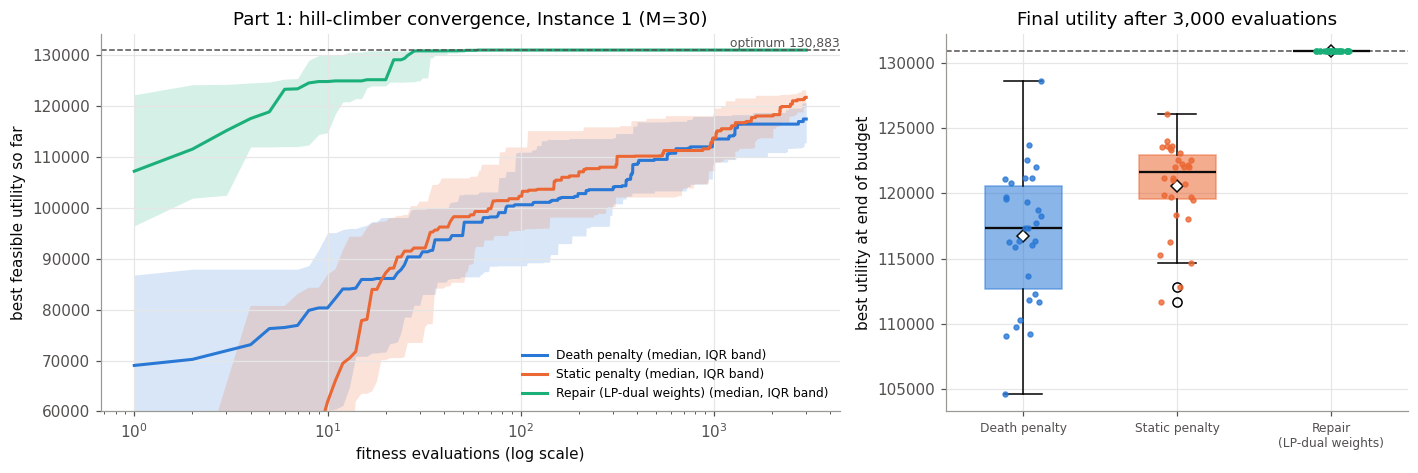

Repair HC: evaluations needed to reach the optimum  min=8  median=56  max=120
Repair vs Death penalty  : Mann-Whitney U=900, p=6.04e-13, A12=1.00 (large)
Repair vs Static penalty : Mann-Whitney U=900, p=6.05e-13, A12=1.00 (large)


In [12]:
cols3 = [C["blue"], C["orange"], C["aqua"]]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw={"width_ratios": [1.6, 1]})
plot_convergence(axes[0], p1_tr, cols3, I1.optimum, "Part 1: hill-climber convergence, Instance 1 (M=30)",
                 ylim=(60_000, 134_000))
plot_box(axes[1], {k: p1_df.loc[p1_df.variant == k, "best_utility"].values for k in p1_handlers},
         cols3, "Final utility after 3,000 evaluations", optimum=I1.optimum)
plt.tight_layout(); plt.show()

rep = p1_df[p1_df.variant == "Repair (LP-dual weights)"]
print("Repair HC: evaluations needed to reach the optimum  "
      f"min={rep.evals_to_opt.min():.0f}  median={rep.evals_to_opt.median():.0f}  max={rep.evals_to_opt.max():.0f}")
for other in ("Death penalty", "Static penalty"):
    r = compare(rep.best_utility, p1_df.loc[p1_df.variant == other, "best_utility"], "greater")
    print(f"Repair vs {other:15s}: Mann-Whitney U={r['U']:.0f}, p={r['p']:.2e}, A12={r['A12']:.2f} ({r['effect']})")

### 1.2 Discussion of baseline results
* **Constraint handling matters more than the search operator.** With the same moves, acceptance rule and budget, the repair-based climber finds the proven optimum (130,883) in **every one of the 30 runs**, typically within a few dozen evaluations. The death- and static-penalty climbers **never** reach it and spread widely across runs (see table and boxplot). All differences are significant (Mann–Whitney p ≪ 0.001, A12 = 1.0).
* **Why the penalty climbers fail.** About half of all moves are rejected outright (death penalty) or land in the heavily penalised infeasible region (static penalty, see "feasible cand. %"). Near the boundary a penalty climber can only remove a model or swap two models of very similar load, so it gets stuck on many local optima. Restarts help, but 3,000 evaluations are not enough.
* **Why repair succeeds.** Every repaired candidate is feasible and *maximal*: the ADD phase fills spare capacity with the best-ratio models, so each evaluation tests a complete, sensible solution. A "flip" becomes "force model j in, then re-optimise the rest", a much larger and more informed step. The move-preserving `keep`/`ban` rule ensures this step always differs from the current solution.
* **Cost.** Repair costs extra CPU per evaluation (≈ 2.5× more µs/eval, see table). On this instance that is negligible, since a full run takes well under a second.

Instance 1 is easy for an informed local search. Part 2 moves to the 90-model instance (≈10²⁷ states) with a population-based method.

---
## Part 2: Advanced metaheuristic (Instance 2, n = 90, m = 5)

### 2.1 Algorithm choice: steady-state GA with surrogate-repair (after Chu & Beasley, 1998)
The Chu–Beasley GA is a strong, well-documented population method for the 0-1 multidimensional knapsack problem, tested on the OR-Library benchmarks that include this problem class. I reimplemented its core ideas from scratch and made three engineering changes: a **move-agnostic repair interface** shared with Part 1, **pre-evaluation duplicate rejection** with an O(1) hash set (no budget wasted), and a **budgeted evaluator** that makes every comparison budget-exact.

### 2.2 Operator rationale
| Component | Choice | Why (and why not the alternatives) |
|---|---|---|
| Population model | steady-state, μ = 100, replace-worst-if-not-worse | A child joins the population immediately and can become a parent in the next step, which exploits good children faster than a generational GA under a tight budget. Replacing only the worst member gives **implicit elitism** |
| Selection | binary tournament | low, constant selection pressure (diversity is kept) and O(1) cost. Insensitive to fitness scaling, unlike roulette wheel, where utilities around 11,000 with small differences would give near-uniform selection |
| Crossover | **uniform** | Model indices have **no meaningful order**, so there is no positional linkage for one- or two-point crossover to preserve. Those operators would only add positional bias (models with nearby indices tend to be inherited together). Uniform crossover has no positional bias (Syswerda, 1989) and mixes the models that both parents agree on with an unbiased choice elsewhere |
| Mutation | bit-flip, pₘ = 1/n (≈ 1 flip per child) | a small change to the parental genotype. The repair then rebalances the change, so the effective step is larger without destroying inherited structure |
| Constraint handling | **greedy DROP/ADD repair, LP-dual surrogate weights** | Every evaluated child is feasible and maximal (no evaluations wasted on infeasible solutions). The dual prices measure how scarce each resource is: only resource 2 has y > 0, so the ratio $p_j / y_2 r_{2j}$ ranks models by utility per unit of the *binding* resource, which matches the structure of the LP optimum |
| Diversity | duplicate rejection | stops the population collapsing onto copies of the incumbent, which is a known failure mode of steady-state GAs with Lamarckian repair |

**Cost per child:** O(n) crossover/mutation + O(n·m) repair + O(n·m) evaluation. The ratio order is computed once per run.

In [13]:
P2_BUDGET = 5_000
p2_ga, p2_ga_tr, p2_div = run_many(steady_state_ga, I2, dual_repair, P2_BUDGET, label="Steady-state GA + dual repair")
p2_hc, p2_hc_tr, _ = run_many(hill_climber, I2, dual_repair, P2_BUDGET, label="Hill climber + dual repair (Part 1 baseline)")
p2_df = pd.concat([p2_ga, p2_hc], ignore_index=True)
summarise(p2_df)

,mean,std,median,best,worst,mean gap %,success %,median evals→opt,feasible cand. %,time/run (s),µs / eval,dup. skipped / run
variant,,,,,,,,,,,,
Steady-state GA + dual repair,11191.0,0.0,11191.0,11191.0,11191.0,0.0,100.0,340.0,100.0,4.32,864.81,16449.5
Hill climber + dual repair (Part 1 baseline),11191.0,0.0,11191.0,11191.0,11191.0,0.0,100.0,293.5,100.0,0.90,179.15,NaN


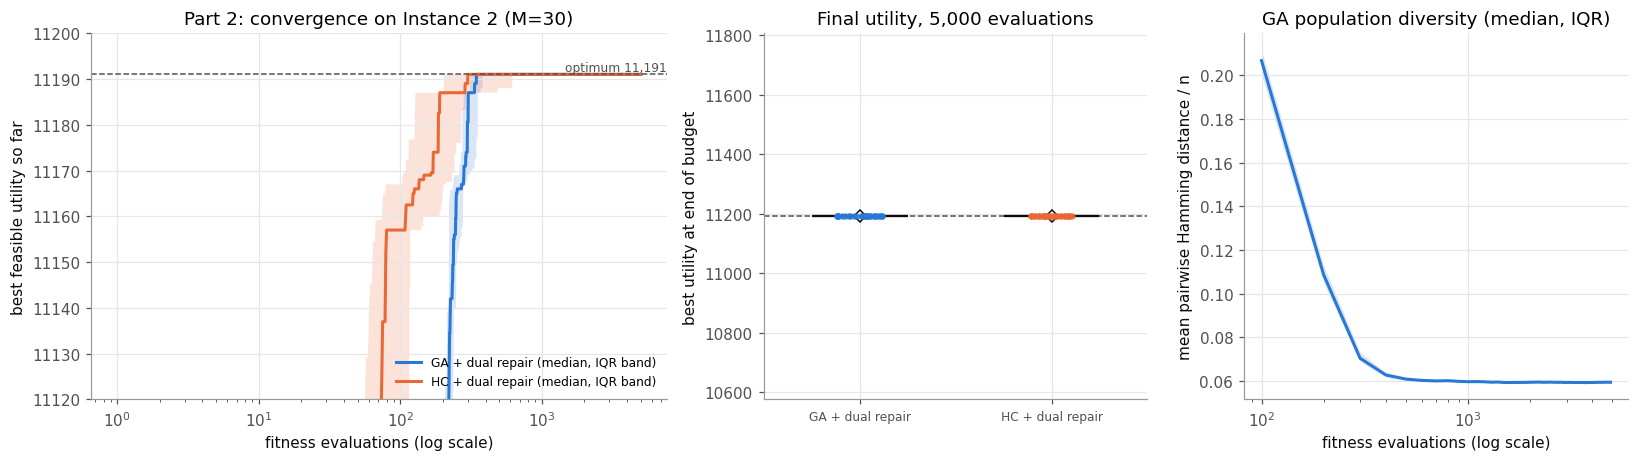

Evaluations to optimum, GA vs HC: median 340 vs 294, two-sided Mann-Whitney p=0.40, A12=0.56 (small)


In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), gridspec_kw={"width_ratios": [1.5, 1, 1]})
plot_convergence(axes[0], {"GA + dual repair": p2_ga_tr, "HC + dual repair": p2_hc_tr},
                 [C["blue"], C["orange"]], I2.optimum, "Part 2: convergence on Instance 2 (M=30)",
                 ylim=(11_120, 11_200))
plot_box(axes[1], {"GA + dual repair": p2_ga.best_utility.values, "HC + dual repair": p2_hc.best_utility.values},
         [C["blue"], C["orange"]], f"Final utility, {P2_BUDGET:,} evaluations", optimum=I2.optimum)
D = np.array([d[:min(map(len, p2_div))] for d in p2_div])
xs = 100 * np.arange(1, D.shape[1] + 1)
axes[2].fill_between(xs, *np.percentile(D, [25, 75], axis=0), color=C["blue"], alpha=0.18, lw=0)
axes[2].plot(xs, np.median(D, 0), color=C["blue"])
axes[2].set(xscale="log", xlabel="fitness evaluations (log scale)", ylabel="mean pairwise Hamming distance / n",
            title="GA population diversity (median, IQR)")
plt.tight_layout(); plt.show()

r = compare(p2_ga.evals_to_opt.fillna(P2_BUDGET + 1), p2_hc.evals_to_opt.fillna(P2_BUDGET + 1), "two-sided")
print(f"Evaluations to optimum, GA vs HC: median {r['median A']:.0f} vs {r['median B']:.0f}, "
      f"two-sided Mann-Whitney p={r['p']:.2f}, A12={r['A12']:.2f} ({r['effect']})")

In [15]:
best = p2_ga.loc[p2_ga.best_utility.idxmax()]
rng = np.random.default_rng(MASTER_SEED + int(best.run))
_, ev_best, _ = steady_state_ga(I2, dual_repair(I2), P2_BUDGET, rng)     # re-run the best seed to recover x
x_best = ev_best.best_x
print(f"Best GA solution (run {int(best.run)}): utility = {I2.p @ x_best:,.0f}  "
      f"(optimum {I2.optimum:,.0f}), {x_best.sum()} of 90 models deployed")
print("deployed model indices:", np.flatnonzero(x_best).tolist())
pd.DataFrame({"resource": [f"R{i+1}" for i in range(I2.m)], "used": (I2.R @ x_best).astype(int),
              "capacity": I2.b.astype(int), "utilisation %": 100 * (I2.R @ x_best) / I2.b,
              "LP dual price": I2.duals, "within capacity": (I2.R @ x_best) <= I2.b})

Best GA solution (run 0): utility = 11,191  (optimum 11,191), 51 of 90 models deployed
deployed model indices: [0, 4, 6, 8, 9, 10, 11, 12, 15, 17, 18, 21, 22, 25, 29, 30, 33, 34, 38, 39, 41, 42, 47, 48, 49, 50, 51, 53, 55, 57, 58, 59, 60, 61, 62, 63, 65, 66, 68, 69, 72, 73, 75, 77, 81, 82, 84, 85, 86, 87, 89]


,resource,used,capacity,utilisation %,LP dual price,within capacity
0,R1,1777,2100,84.62,0.00,True
1,R2,1100,1100,100.00,2.77,True
2,R3,2259,3300,68.45,0.00,True
3,R4,2232,3700,60.32,0.00,True
4,R5,2418,3600,67.17,0.00,True


### 2.3 Discussion
* The GA reaches the **proven optimum (11,191) in 30/30 runs**, at a median of a few hundred evaluations. That is a vanishing fraction (~10⁻²⁴) of the 2⁹⁰ search space. The audit table confirms feasibility independently: resource 2 is used to exactly 100 %, the binding constraint predicted by the LP dual, and all other resources have slack.
* **Honest negative result:** the repair-based hill climber from Part 1 *also* reaches the optimum in 30/30 runs, with no significant difference in evaluations-to-optimum (two-sided test above). With one binding resource and a near-optimal greedy ordering (§3.2 shows the dual greedy alone is within 0.21 % of optimal), the repair does most of the work on this instance, and a good local search is enough. This does not show that the population is unnecessary, so §2.4 tests where it helps.
* **Diversity panel:** diversity starts high (random repaired solutions), falls as selection acts, and settles at a non-zero level. Duplicate rejection prevents total collapse.
* **Hidden cost of duplicate rejection.** Repair maps many different children onto the *same* maximal solution. Once the population has converged, most children are duplicates and are discarded without using budget (`dup. skipped / run`). Each discarded child still costs a crossover, mutation and repair, which is why the GA's µs/eval is several times higher than the climber's. The budget comparison is fair, but CPU time is not equal, and Part 3 (§3.1.2) analyses this trade-off.

### 2.4 Stress test: when does the population help?
Two harder settings remove the advantage a near-perfect greedy ordering gives. Each uses the same two algorithms, M = 30 runs and **3,000 evaluations**:
* **(a) Weaker heuristic:** Instance 2 with the capacity-normalised repair (the weaker ordering, see H2), so the search has to correct a mis-ranked greedy.
* **(b) Harder instance:** Instance 2 with all capacities scaled by 0.3 (*Instance 2-T*). Its LP solution now has **two** binding resources (R1 and R2), so no single ratio ranks the models correctly. The exact optimum is again computed by MILP, for reporting only.

In [16]:
import copy
I2T = copy.deepcopy(I2)
I2T.name, I2T.b = "Instance 2-T (capacities x 0.3)", np.floor(0.3 * I2.b)
solve_reference(I2T)
print(f"{I2T.name}: b = {I2T.b.astype(int)}, optimum = {I2T.optimum:,.0f}, LP duals = {np.round(I2T.duals, 2)}")

STRESS_BUDGET = 3_000
stress = {}
for tag, I, H in [("(a) Instance 2, normalised repair", I2, naive_repair),
                  ("(b) Instance 2-T, dual repair", I2T, dual_repair)]:
    ga_df, ga_tr, _ = run_many(steady_state_ga, I, H, STRESS_BUDGET, label="GA")
    hc_df, hc_tr, _ = run_many(hill_climber, I, H, STRESS_BUDGET, label="HC")
    stress[tag] = (I, ga_df, ga_tr, hc_df, hc_tr)
    s = summarise(pd.concat([ga_df, hc_df]))[["mean", "std", "worst", "success %", "median evals→opt", "time/run (s)"]]
    r = compare(ga_df.best_utility, hc_df.best_utility, "greater")
    print(f"\n{tag}:  GA > HC one-sided Mann-Whitney p={r['p']:.2e}, A12={r['A12']:.2f} ({r['effect']})")
    display(s)

Instance 2-T (capacities x 0.3): b = [ 630  330  990 1110 1080], optimum = 7,168, LP duals = [2.67 4.93 0.   0.   0.  ]



(a) Instance 2, normalised repair:  GA > HC one-sided Mann-Whitney p=2.01e-08, A12=0.85 (large)


,mean,std,worst,success %,median evals→opt,time/run (s)
variant,,,,,,
GA,11191.00,0.00,11191.0,100.0,659.0,1.33
HC,11183.97,9.03,11160.0,30.0,1212.0,0.56



(b) Instance 2-T, dual repair:  GA > HC one-sided Mann-Whitney p=2.59e-07, A12=0.80 (large)


,mean,std,worst,success %,median evals→opt,time/run (s)
variant,,,,,,
GA,7168.0,0.00,7168.0,100.0,171.0,2.91
HC,7154.8,10.96,7146.0,40.0,1505.0,0.77


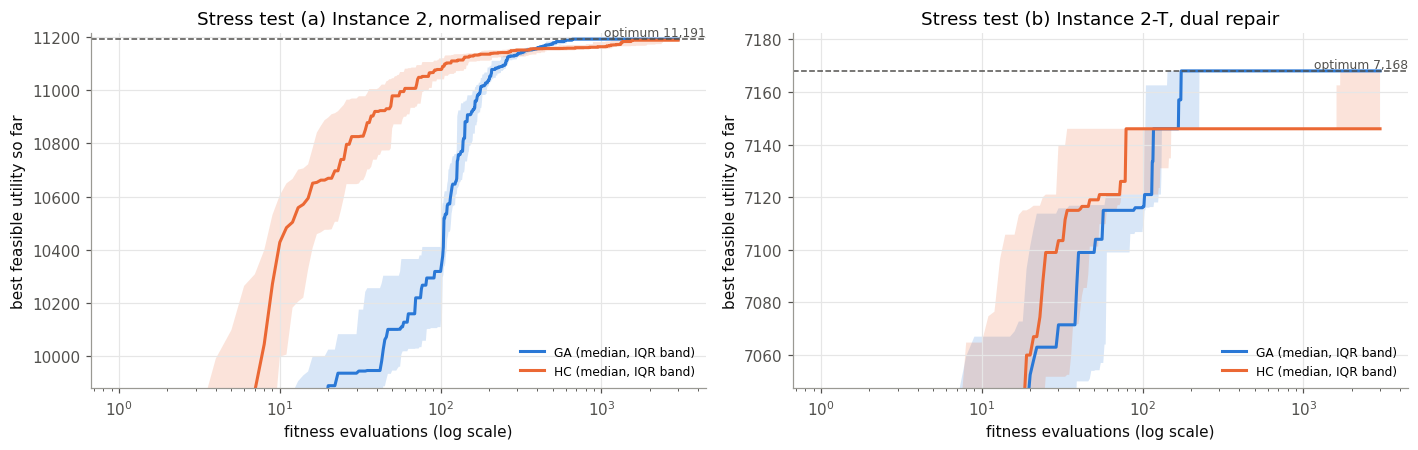

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, (tag, (I, ga_df, ga_tr, hc_df, hc_tr)) in zip(axes, stress.items()):
    lo = np.percentile(np.concatenate([ga_tr[:, 50], hc_tr[:, 50]]), 10)
    plot_convergence(ax, {"GA": ga_tr, "HC": hc_tr}, [C["blue"], C["orange"]], I.optimum,
                     f"Stress test {tag}", ylim=(lo, I.optimum + 0.002 * I.optimum))
plt.tight_layout(); plt.show()

**Stress-test interpretation.** In both harder settings the GA reaches the optimum far more reliably than the climber, a significant, large effect (see outputs). With a mis-ranked greedy (a), the climber's single-model exchanges often get stuck at a repaired local optimum, and its restarts land in a similar basin because the same biased repair is applied again. The GA recombines models that *different* individuals got right, which corrects ranking errors that no single neighbour move can fix. With two binding resources (b), improving moves increasingly require exchanging several models at once to rebalance both constraints. Uniform crossover followed by repair makes such multi-model moves naturally, while the climber's moves are mostly one or two models at a time. **Conclusion for Part 2:** the GA is the more robust design. On the benign original instance its advantage is hidden by a very informative repair, but it appears as soon as the problem or the heuristic becomes less favourable.

---
## Part 3: Empirical study and hypothesis testing (Instance 2)

### 3.0 Protocol (common to both experiments)
* **Equal budget:** 5,000 fitness evaluations per run, counted by the shared `Evaluator`, so no variant can evaluate more.
* **M = 30 independent runs per variant.** Run *k* of each variant starts from seed 42 + k (common random numbers at initialisation). The random streams diverge after the first different decision, so the samples are treated as **independent**.
* **Everything except the factor under test is held fixed:** steady-state GA, μ = 100, binary tournament, uniform crossover, pₘ = 1/n, duplicate rejection.
* **Statistics:** one-sided **Mann–Whitney U** (non-parametric, no normality assumption; utility distributions are bounded and skewed at the optimum), α = 0.05, plus the **Vargha–Delaney A12** effect size, as recommended for randomised algorithms by Arcuri & Briand (2011). When one experiment tests several checkpoints, the p-values are **Holm-corrected**.

### 3.1 Experiment A: repair vs penalty (constraint-handling paradigm)
**Hypothesis H1.** *A GA that repairs every child (LP-dual repair) achieves higher final utility than an otherwise identical GA using a static penalty function, under an equal evaluation budget.*

**Reasoning.** The optimum lies on the boundary of the binding resource (R2 at 100 %). A penalty GA must approach that boundary through selection pressure alone. Part of its budget goes on infeasible children that cannot become the incumbent, and uniform crossover of two near-boundary feasible parents often produces an overfull child. Repair projects every child onto a maximal feasible point, so every evaluation is a usable candidate. **Counter-hypothesis (trade-off):** the penalty GA is much cheaper per evaluation, so under equal *wall-clock time* it might close the gap. This is tested as a secondary analysis (§3.1.2).

H0: the distributions of final utility are equal; H1 (one-sided): Repair > Penalty.

In [18]:
P3_BUDGET = 5_000
A_rep, A_rep_tr, _ = run_many(steady_state_ga, I2, dual_repair, P3_BUDGET, label="Repair (LP-dual weights)")
A_pen, A_pen_tr, _ = run_many(steady_state_ga, I2, StaticPenalty, P3_BUDGET, label="Static penalty")
A_df = pd.concat([A_rep, A_pen], ignore_index=True)
summarise(A_df)

,mean,std,median,best,worst,mean gap %,success %,median evals→opt,feasible cand. %,time/run (s),µs / eval,dup. skipped / run
variant,,,,,,,,,,,,
Repair (LP-dual weights),11191.00,0.00,11191.0,11191.0,11191.0,0.00,100.0,340.0,100.00,4.24,847.12,16449.5
Static penalty,11155.53,22.07,11157.0,11187.0,11112.0,0.32,0.0,NaN,58.73,0.55,109.44,196.3


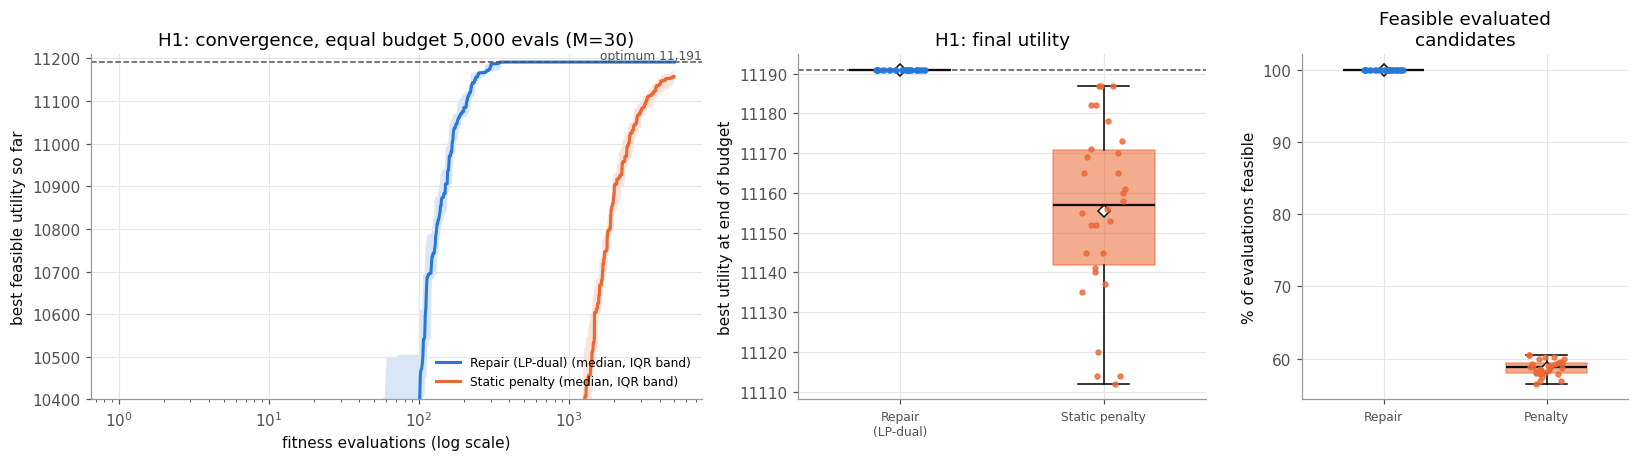

H1  Repair vs Penalty: median 11,191 vs 11,157;  U=900, p=6.01e-13, A12=1.00 (large)  ->  reject H0 at alpha=0.05
CPU cost per evaluation: repair 847 µs, penalty 109 µs  ->  ratio 7.7x


In [19]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), gridspec_kw={"width_ratios": [1.5, 1, 0.8]})
plot_convergence(axes[0], {"Repair (LP-dual)": A_rep_tr, "Static penalty": A_pen_tr},
                 [C["blue"], C["orange"]], I2.optimum, "H1: convergence, equal budget 5,000 evals (M=30)",
                 ylim=(10_400, 11_210))
plot_box(axes[1], {"Repair (LP-dual)": A_rep.best_utility.values, "Static penalty": A_pen.best_utility.values},
         [C["blue"], C["orange"]], "H1: final utility", optimum=I2.optimum)
plot_box(axes[2], {"Repair": 100 * A_rep.feasible_rate.values, "Penalty": 100 * A_pen.feasible_rate.values},
         [C["blue"], C["orange"]], "Feasible evaluated\ncandidates", ylabel="% of evaluations feasible")
plt.tight_layout(); plt.show()

rA = compare(A_rep.best_utility, A_pen.best_utility, "greater")
print(f"H1  Repair vs Penalty: median {rA['median A']:,.0f} vs {rA['median B']:,.0f};  U={rA['U']:.0f}, "
      f"p={rA['p']:.2e}, A12={rA['A12']:.2f} ({rA['effect']})  ->  "
      f"{'reject H0' if rA['p'] < 0.05 else 'cannot reject H0'} at alpha=0.05")
t_rep = A_rep.time_s.sum() / A_rep.evals_used.sum(); t_pen = A_pen.time_s.sum() / A_pen.evals_used.sum()
print(f"CPU cost per evaluation: repair {1e6*t_rep:.0f} µs, penalty {1e6*t_pen:.0f} µs  ->  ratio {t_rep/t_pen:.1f}x")

#### 3.1.2 Secondary analysis: equal wall-clock time
Evaluation budgets are the standard fairness criterion, but repair hides extra computation inside `prepare()`. To check whether H1 only holds because evaluations are counted rather than timed, the penalty GA is rerun with a budget that gives it roughly the **same total CPU time** as the repair GA. The budget is fixed at **37,500 evaluations** (= 5,000 × 7.5): the cost ratio measured on the development machine was 7.5×, and the cell above prints the ratio on the current machine. A fixed number keeps the result reproducible.

In [20]:
EQ_TIME_BUDGET = 37_500
A_pen_eq, A_pen_eq_tr, _ = run_many(steady_state_ga, I2, StaticPenalty, EQ_TIME_BUDGET, label="Static penalty, 37.5k evals (≈ equal time)")
display(summarise(pd.concat([A_rep, A_pen_eq], ignore_index=True)))
rA2 = compare(A_rep.best_utility, A_pen_eq.best_utility, "greater")
print(f"Repair(5k) vs Penalty(37.5k): p={rA2['p']:.2e}, A12={rA2['A12']:.2f} ({rA2['effect']})")

,mean,std,median,best,worst,mean gap %,success %,median evals→opt,feasible cand. %,time/run (s),µs / eval,dup. skipped / run
variant,,,,,,,,,,,,
Repair (LP-dual weights),11191.00,0.00,11191.0,11191.0,11191.0,0.00e+00,100.00,340.0,100.00,4.24,847.12,16449.50
"Static penalty, 37.5k evals (≈ equal time)",11190.87,0.73,11191.0,11191.0,11187.0,1.19e-03,96.67,10124.0,46.94,4.07,108.44,3032.13


Repair(5k) vs Penalty(37.5k): p=1.67e-01, A12=0.52 (negligible)


### 3.2 Experiment B: which surrogate weights should the repair use?
Experiment A shows that repair wins. The follow-up question is what makes a repair heuristic good, which is the part of the design most specific to this problem.

**Hypothesis H2.** *Repair ordered by LP-dual surrogate ratios $p_j/\sum_i y_i r_{ij}$ reaches the optimum in fewer evaluations than repair ordered by the capacity-normalised ratio $p_j/\sum_i r_{ij}/b_i$ (the common default, also used in the module's lab notebook).*

**Reasoning (from §0.1).** Only resource 2 is scarce (y₂ > 0, all other y = 0). The capacity-normalised ratio adds four **non-binding** resources to the cost denominator. A model that is cheap on R2 but heavy on the slack resources is then ranked low and dropped first, although removing it frees almost none of the resource that is actually short. The dual ratio prices the slack resources at zero, so DROP removes the models with the least utility per unit of R2 and ADD fills R2 most profitably.

**Metrics.** (i) evaluations needed to reach the proven optimum (*run-length*; runs that never reach it are censored at budget + 1, which preserves their rank), and (ii) best utility at fixed checkpoints of 100 / 250 / 500 / 1,000 evaluations (anytime performance; Holm-corrected).
H0: equal distributions. H1 (one-sided): dual repair needs fewer evaluations and has higher anytime utility.

In [21]:
# mechanism evidence: how different are the two rankings, and how good is each greedy on its own?
Hd, Hn = dual_repair(I2), naive_repair(I2)
rho = spearmanr(Hd.ratio, Hn.ratio).statistic
g_d = I2.p @ Hd.prepare(np.zeros(I2.n, np.int8)); g_n = I2.p @ Hn.prepare(np.zeros(I2.n, np.int8))
print(f"Spearman rank correlation of the two pseudo-utility orderings: rho = {rho:.2f}")
print(f"Pure greedy (ADD from empty), no search: dual = {g_d:,.0f} (gap {100*(I2.optimum-g_d)/I2.optimum:.2f} %), "
      f"normalised = {g_n:,.0f} (gap {100*(I2.optimum-g_n)/I2.optimum:.2f} %)")

# Variant A = the LP-dual repair GA already run in Experiment A (identical configuration, seeds and budget)
B_nai, B_nai_tr, _ = run_many(steady_state_ga, I2, naive_repair, P3_BUDGET, label="Repair (capacity-normalised weights)")
B_df = pd.concat([A_rep, B_nai], ignore_index=True)
summarise(B_df)

Spearman rank correlation of the two pseudo-utility orderings: rho = 0.84
Pure greedy (ADD from empty), no search: dual = 11,167 (gap 0.21 %), normalised = 10,819 (gap 3.32 %)


,mean,std,median,best,worst,mean gap %,success %,median evals→opt,feasible cand. %,time/run (s),µs / eval,dup. skipped / run
variant,,,,,,,,,,,,
Repair (LP-dual weights),11191.0,0.0,11191.0,11191.0,11191.0,0.0,100.0,340.0,100.0,4.24,847.12,16449.50
Repair (capacity-normalised weights),11191.0,0.0,11191.0,11191.0,11191.0,0.0,100.0,659.0,100.0,2.23,445.69,5784.57


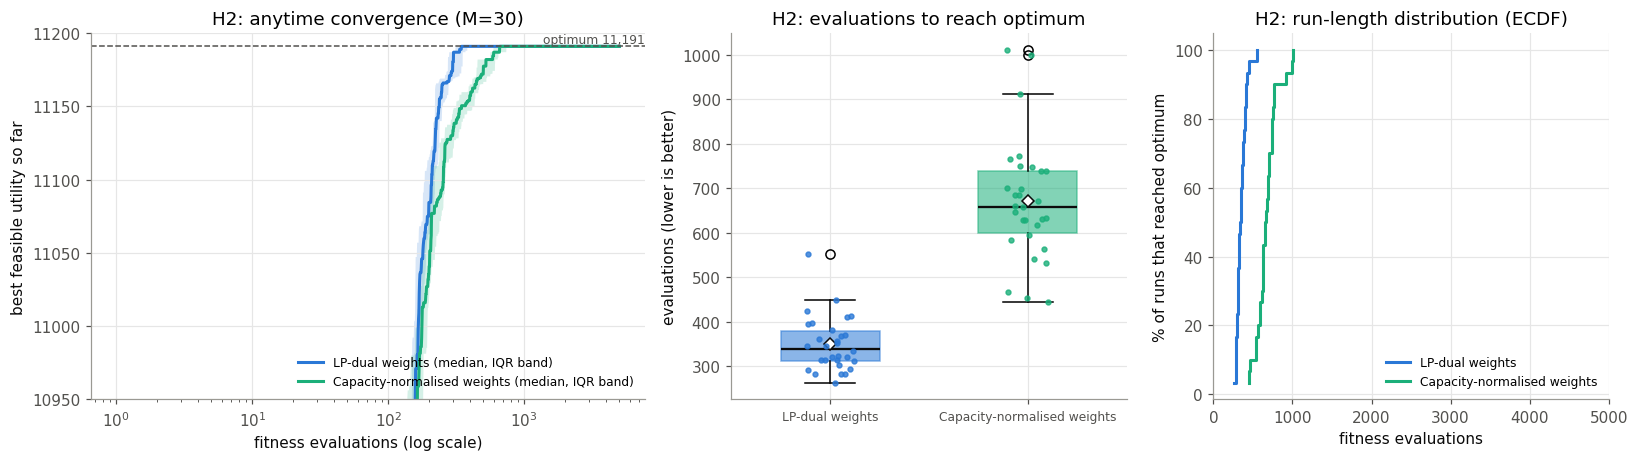

,metric,median dual,median normalised,U,p,A12,effect,p (Holm),A12 note,reject H0 (α=0.05)
0,evaluations to optimum (lower better),340.0,659.0,6.0,2.74e-11,6.67e-03,large,1.37e-10,A12<0.5 = dual faster,True
1,best utility @ 100 evals,10372.5,10318.5,594.5,1.66e-02,6.61e-01,medium,3.33e-02,A12>0.5 = dual better,True
2,best utility @ 250 evals,11165.0,11093.0,829.5,1.03e-08,9.22e-01,large,3.10e-08,A12>0.5 = dual better,True
3,best utility @ 500 evals,11191.0,11177.0,853.5,4.01e-11,9.48e-01,large,1.61e-10,A12>0.5 = dual better,True
4,best utility @ 1000 evals,11191.0,11191.0,465.0,1.67e-01,5.17e-01,negligible,1.67e-01,A12>0.5 = dual better,False


In [22]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), gridspec_kw={"width_ratios": [1.4, 1, 1]})
plot_convergence(axes[0], {"LP-dual weights": A_rep_tr, "Capacity-normalised weights": B_nai_tr},
                 [C["blue"], C["aqua"]], I2.optimum, "H2: anytime convergence (M=30)", ylim=(10_950, 11_200))
rl = {"LP-dual weights": A_rep.evals_to_opt.fillna(P3_BUDGET + 1).values,
      "Capacity-normalised weights": B_nai.evals_to_opt.fillna(P3_BUDGET + 1).values}
plot_box(axes[1], rl, [C["blue"], C["aqua"]], "H2: evaluations to reach optimum", ylabel="evaluations (lower is better)")
for (k, v), col in zip(rl.items(), [C["blue"], C["aqua"]]):      # run-length distribution (ECDF)
    s = np.sort(v); axes[2].step(s, np.arange(1, s.size + 1) / s.size * 100, where="post", color=col, label=k)
axes[2].set(xlabel="fitness evaluations", ylabel="% of runs that reached optimum",
            title="H2: run-length distribution (ECDF)", xlim=(0, P3_BUDGET)); axes[2].legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

rows = [{"metric": "evaluations to optimum (lower better)",
         **compare(rl["LP-dual weights"], rl["Capacity-normalised weights"], "less")}]
for cp in (100, 250, 500, 1000):
    rows.append({"metric": f"best utility @ {cp} evals",
                 **compare(A_rep_tr[:, cp - 1], B_nai_tr[:, cp - 1], "greater")})
H2 = pd.DataFrame(rows)
H2["p (Holm)"] = holm(H2.p)
H2["A12 note"] = ["A12<0.5 = dual faster"] + ["A12>0.5 = dual better"] * 4
H2["reject H0 (α=0.05)"] = H2["p (Holm)"] < 0.05
H2.rename(columns={"median A": "median dual", "median B": "median normalised"})

### 3.3 Results and discussion

**H1 (repair vs penalty): supported.** Under an equal budget of 5,000 evaluations, the repair GA reaches the optimum in every run. The penalty GA never reaches it, and finishes lower and more variably. The difference is large and highly significant (A12 = 1.0). The feasibility panel shows the mechanism: about 41 % of the penalty GA's evaluations go on infeasible children, which can never become the incumbent and only shape selection. Every repair evaluation is a feasible, maximal candidate.

**H1 under equal wall-clock time: not supported.** Measured over the whole run, the repair GA costs ≈ 7.5× more CPU per evaluation. With 37,500 evaluations (≈ the same total time, see the `time/run` column), the penalty GA reaches the optimum in 29/30 runs, and the difference from repair is no longer significant (p ≈ 0.17, A12 ≈ 0.52, negligible). The advantage of repair is therefore an *evaluation-efficiency* advantage. If fitness evaluations were expensive (e.g. profiling each model selection on real hardware), repair would clearly be preferable. With a cheap linear objective, as here, a penalty GA given enough time also gets there.

Two details keep this conclusion fair to repair:
* **Most of the 7.5× is duplicate churn, not repair.** After converging (median 340 evaluations), the repair GA keeps producing children that repair maps back onto existing population members: about 16,000 are discarded per run (`dup. skipped / run`). In the hill climber, which has no duplicate check, repair costs only ≈ 2× a plain evaluation (Part 1/2 µs/eval). A stopping rule or a stronger perturbation on duplicates would remove most of this overhead. This is an engineering improvement identified by this experiment.
* **Time to reach the optimum still favours repair.** Repair needs a median of 340 evaluations × ≤ 0.8 ms ≈ ≤ 0.3 s (an upper bound, since duplicates concentrate after convergence). The penalty GA needs ≈ 10,100 evaluations × 0.11 ms ≈ 1.1 s.

This is the central **quality vs constraint-efficiency vs time** trade-off:

| | Repair (LP-dual) | Static penalty |
|---|---|---|
| Solution quality | optimum in 30/30 runs (5k evals) | optimum in 0/30 runs at 5k evals, 29/30 at 37.5k (≈ equal time) |
| Constraint enforcement | 100 % of evaluated candidates feasible. Feasibility guaranteed by construction | ~41 % (5k) to 53 % (37.5k) of evaluations infeasible. Feasibility depends on choosing λ correctly |
| CPU per evaluation | high: ≈ 2× from the O(n·m) repair, plus duplicate churn after convergence | low (one matrix–vector product) |
| Problem knowledge needed | ratio order (LP duals) | only λ |
| Fragility | a poor weighting slows it down (H2) | λ too small → infeasible optima. λ too large → boundary avoided |

**H2 (dual vs capacity-normalised weights): supported.** Both repairs eventually reach the optimum, since the GA can make up for a weaker heuristic given enough evaluations. The dual-weighted repair gets there in significantly fewer evaluations: about half as many at the median, with a large effect size. After Holm correction it also has significantly higher anytime utility at 100, 250 and 500 evaluations. By 1,000 evaluations both variants have converged and the difference is no longer significant. The mechanism checks agree. The two orderings are strongly but not perfectly correlated (Spearman ρ ≈ 0.84), and the models they disagree on are exactly the ones that decide the optimum. The dual greedy alone, with no search at all, is already within 0.21 % of the optimum, while the normalised greedy is 3.3 % away. The normalised repair also costs *less* CPU per evaluation, because it converges later and so generates fewer duplicate children. The faster heuristic is not the cheaper one per evaluation. A better ratio gives a better starting population *and* a stronger projection for every child. **The repair heuristic is where problem structure enters the GA, and the LP dual is a cheap, principled way to obtain it.**

As the budget grows, the H2 checkpoint effects shrink to zero: at 5,000 evaluations both variants reach 11,191 in every run. Choosing a budget that hides this difference would be the opposite mistake to choosing one that exaggerates it, which is why the run-length distribution is reported alongside final quality.

---
## 4. Conclusions and threats to validity
1. **Part 1:** on Instance 1, constraint handling decided the outcome. With identical moves and budget, a move-preserving greedy repair turned a weak hill climber (penalty versions: optimum never found) into one that finds the proven optimum in 30/30 runs.
2. **Part 2:** a from-scratch steady-state GA with LP-dual surrogate repair, uniform crossover and duplicate rejection solves Instance 2 to proven optimality in 30/30 runs, and reaches the optimum significantly faster than the repair-based hill climber.
3. **Part 3:** H1 is supported under equal *evaluation* budgets (A12 = 1.0). It is **not** supported under approximately equal CPU time, where a well-calibrated static penalty catches up (29/30 optimal). The repair GA still reaches the optimum about 4× sooner in wall-clock time, and most of its extra cost is avoidable duplicate churn. H2 is supported: LP-dual weights make the repair about twice as evaluation-efficient as capacity-normalised weights (large effect, Holm-corrected).

**Threats to validity.**
* *External validity:* there is one challenge instance, and it has a single binding constraint. On instances where several resources bind, the dual prices spread out and the H2 advantage should shrink; this would need instances with tighter, correlated constraints (e.g. OR-Library *mknapcb*).
* *Construct validity:* the evaluation count ignores repair cost, so §3.1.2 adds a wall-clock check. Absolute timings depend on the machine; the relative ranking is what matters.
* *Internal validity:* λ was chosen analytically rather than tuned, and an adaptive penalty (Hadj-Alouane & Bean, 1997) was tried during development but never activated, because the best individual stayed feasible. Uniform crossover, pₘ = 1/n and μ = 100 were not tuned per variant. Both variants share them, so the comparison is fair, but a different setting might change effect sizes.
* *Statistical conclusion validity:* M = 30, non-parametric tests, effect sizes and Holm correction for the H2 checkpoint family.

## 5. References
* Arcuri, A. & Briand, L. (2011). A practical guide for using statistical tests to assess randomized algorithms in software engineering. *Proc. ICSE 2011*, 1–10.
* Chu, P. C. & Beasley, J. E. (1998). A genetic algorithm for the multidimensional knapsack problem. *Journal of Heuristics*, 4(1), 63–86.
* Coello Coello, C. A. (2002). Theoretical and numerical constraint-handling techniques used with evolutionary algorithms: a survey of the state of the art. *Computer Methods in Applied Mechanics and Engineering*, 191(11–12), 1245–1287.
* Hadj-Alouane, A. B. & Bean, J. C. (1997). A genetic algorithm for the multiple-choice integer program. *Operations Research*, 45(1), 92–101.
* Holm, S. (1979). A simple sequentially rejective multiple test procedure. *Scandinavian Journal of Statistics*, 6(2), 65–70.
* Olsen, A. L. (1994). Penalty functions and the knapsack problem. *Proc. 1st IEEE Conference on Evolutionary Computation*, 554–558.
* Pirkul, H. (1987). A heuristic solution procedure for the multiconstraint zero-one knapsack problem. *Naval Research Logistics*, 34(2), 161–172.
* Syswerda, G. (1989). Uniform crossover in genetic algorithms. *Proc. 3rd International Conference on Genetic Algorithms*, 2–9.
* Vargha, A. & Delaney, H. D. (2000). A critique and improvement of the CL common language effect size statistics of McGraw and Wong. *Journal of Educational and Behavioral Statistics*, 25(2), 101–132.